# Digital Image Processing – Assignment 4
**Name:** Abisha
**ID:** 232031056

Grayscale image shape: (512, 512)
Colour image shape: (512, 512, 3)


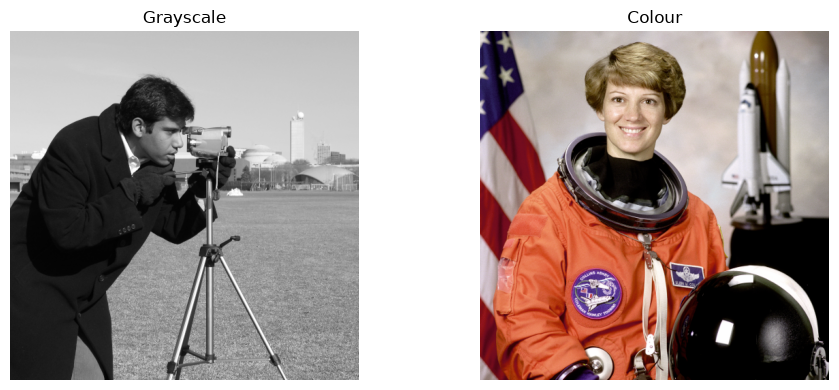

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
import urllib.request

REPO_IMG_BASE = "https://raw.githubusercontent.com/id-232031056/dip/main/images"

def load_image(filename, gray=False):
    url = f"{REPO_IMG_BASE}/{filename}"
    try:
        resp = urllib.request.urlopen(url, timeout=10)
        arr = np.asarray(bytearray(resp.read()), dtype=np.uint8)
        flag = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
        img = cv2.imdecode(arr, flag)
        if img is not None:
            if not gray:
                img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            return img
    except Exception:
        pass
    from skimage import data
    if gray:
        return data.camera()
    return data.astronaut()

img_gray = load_image("test_gray.png", gray=True)
img_color = load_image("test_color.png", gray=False)
print("Grayscale image shape:", img_gray.shape)
print("Colour image shape:", img_color.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(img_gray, cmap='gray'); axes[0].set_title("Grayscale"); axes[0].axis('off')
axes[1].imshow(img_color); axes[1].set_title("Colour"); axes[1].axis('off')
plt.tight_layout(); plt.show()

## Task 4.1 – 2D Correlation with Image Kernels

2D correlation slides a kernel (filter) over the image and computes the sum of element-wise products
at each position. For a kernel of size (2a+1)×(2b+1), the output at pixel (x,y) is:
g(x,y) = Σ_s Σ_t w(s,t) · f(x+s, y+t), where the sum runs over the kernel extent.
Zero-padding is used at image boundaries to maintain the output size.

In [2]:
def correlate2d(image, kernel):
    """Perform 2D correlation manually with zero-padding.
    Works on single-channel (grayscale) images."""
    img = image.astype(np.float64)
    kh, kw = kernel.shape
    pad_h, pad_w = kh // 2, kw // 2

    # Zero-pad the image
    padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode='constant', constant_values=0)

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i + kh, j:j + kw]
            output[i, j] = np.sum(region * kernel)

    return output

# Define standard kernels
kernels = {
    "Box/Average (3×3)": np.ones((3, 3)) / 9.0,
    "Gaussian (3×3)": np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]]) / 16.0,
    "Sobel X": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64),
    "Sobel Y": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64),
    "Laplacian": np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float64),
    "Sharpening": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float64),
}

# Use a reasonably sized image for speed
test_img = img_gray
if test_img.shape[0] > 256:
    test_img = cv2.resize(img_gray, (256, 256))

print("Using image of shape:", test_img.shape)
for name, kern in kernels.items():
    print(f"\nKernel: {name}")
    print(kern)

Using image of shape: (256, 256)

Kernel: Box/Average (3×3)
[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]

Kernel: Gaussian (3×3)
[[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]

Kernel: Sobel X
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Kernel: Sobel Y
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Kernel: Laplacian
[[ 0.  1.  0.]
 [ 1. -4.  1.]
 [ 0.  1.  0.]]

Kernel: Sharpening
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]


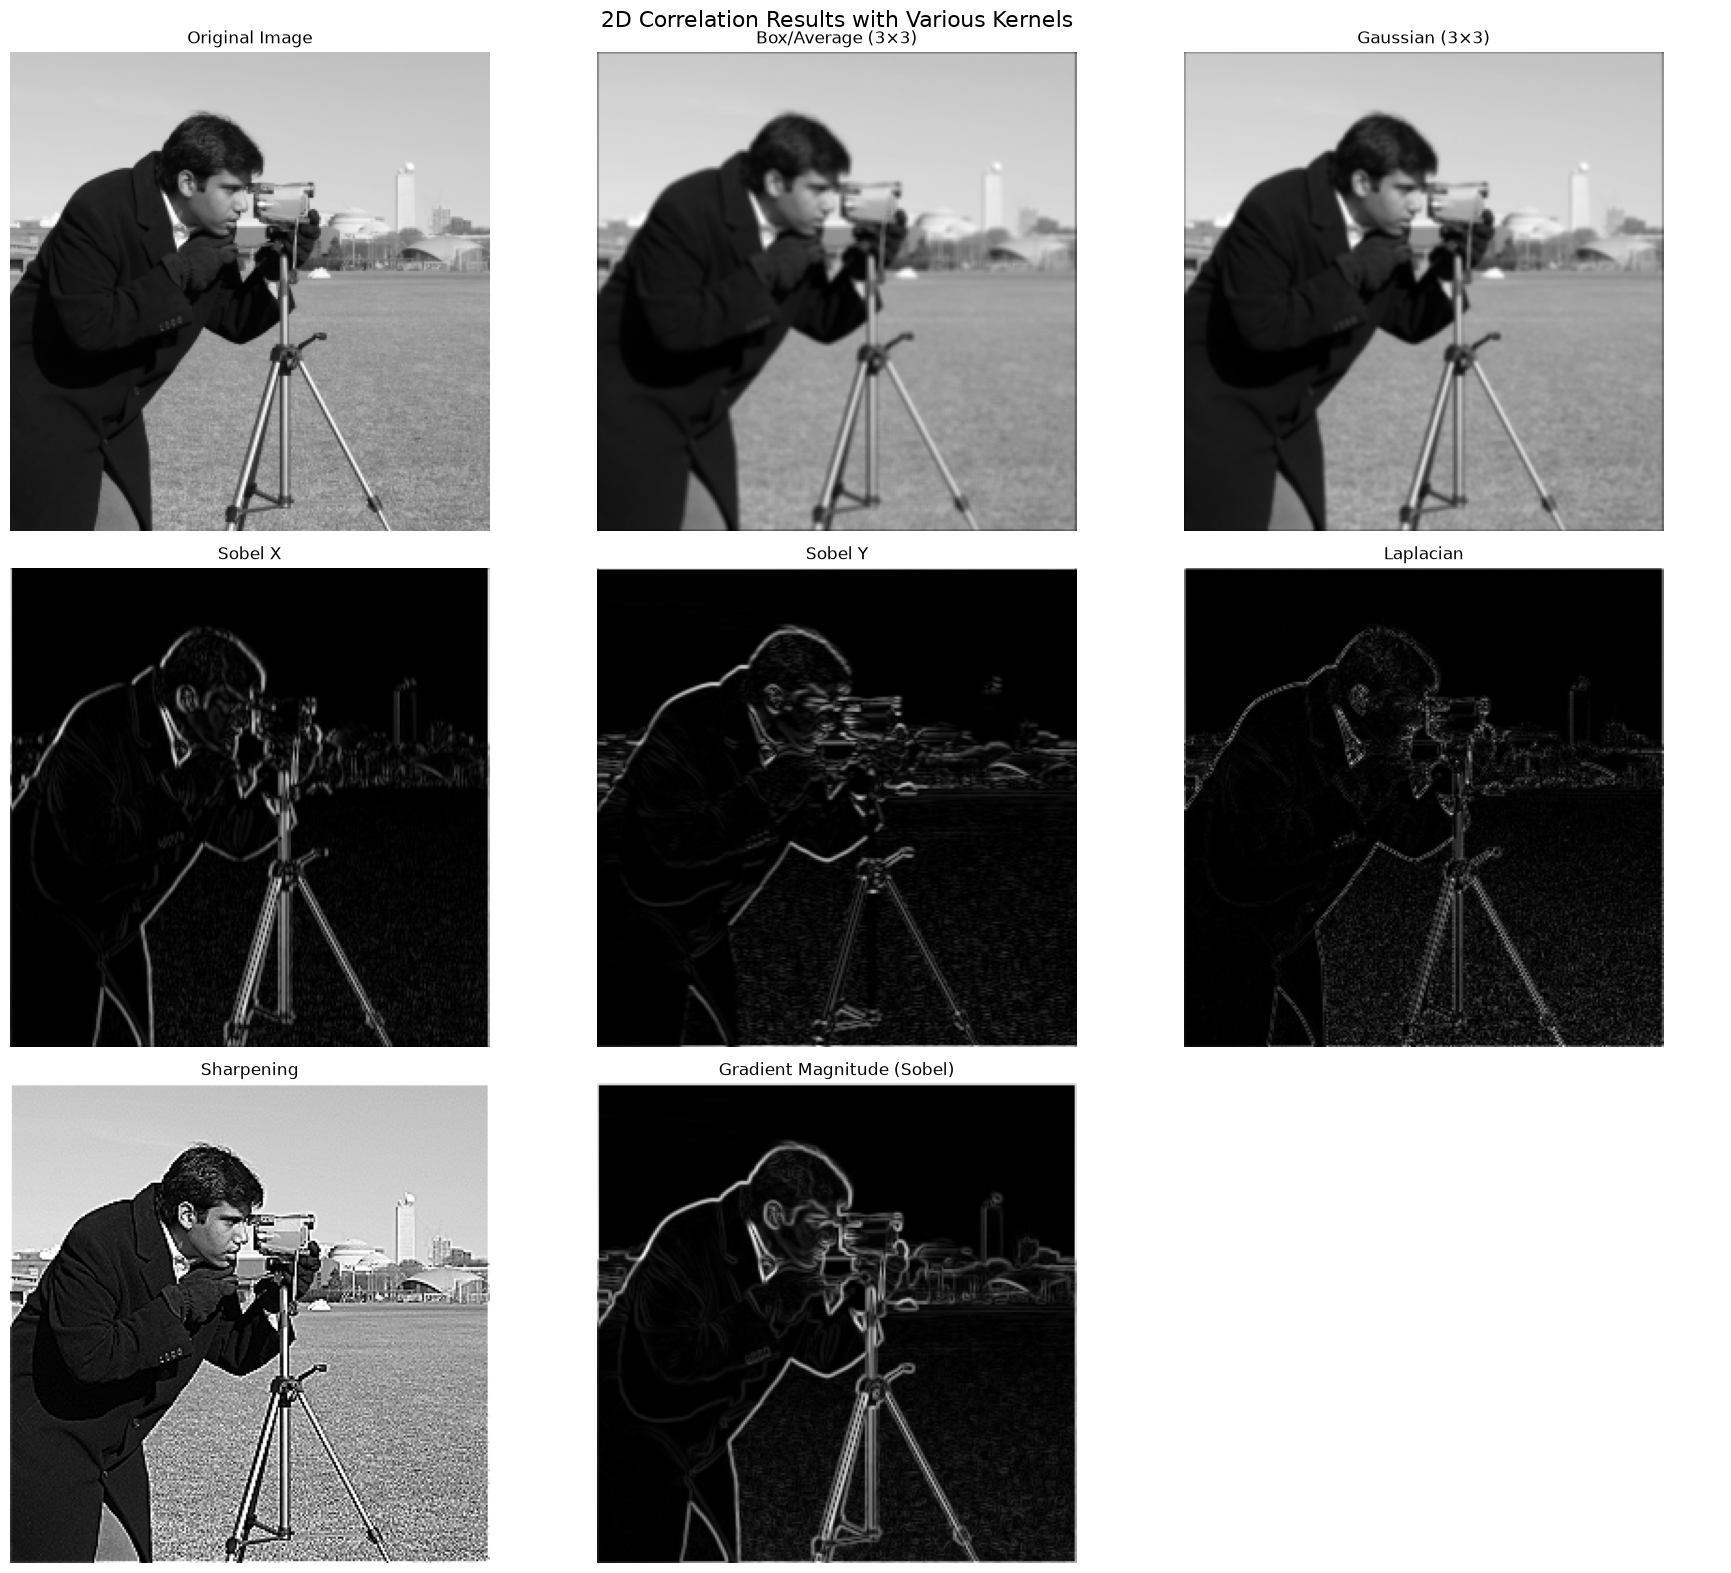

In [3]:
# Apply all kernels and display results
fig, axes = plt.subplots(3, 3, figsize=(18, 16))

# Original
axes[0, 0].imshow(test_img, cmap='gray')
axes[0, 0].set_title("Original Image")
axes[0, 0].axis('off')

# Apply each kernel
results = {}
for idx, (name, kern) in enumerate(kernels.items()):
    result = correlate2d(test_img, kern)
    results[name] = result
    r, col = (idx + 1) // 3, (idx + 1) % 3
    # For edge/gradient kernels, use absolute value for display
    if "Sobel" in name or "Laplacian" in name:
        display = np.abs(result)
        display = (display / display.max() * 255).astype(np.uint8) if display.max() > 0 else display.astype(np.uint8)
    elif "Sharpening" in name:
        display = np.clip(result, 0, 255).astype(np.uint8)
    else:
        display = np.clip(result, 0, 255).astype(np.uint8)
    axes[r, col].imshow(display, cmap='gray')
    axes[r, col].set_title(name)
    axes[r, col].axis('off')

# Gradient magnitude from Sobel
sobel_mag = np.sqrt(results["Sobel X"]**2 + results["Sobel Y"]**2)
sobel_mag = (sobel_mag / sobel_mag.max() * 255).astype(np.uint8)
axes[2, 1].imshow(sobel_mag, cmap='gray')
axes[2, 1].set_title("Gradient Magnitude (Sobel)")
axes[2, 1].axis('off')

axes[2, 2].axis('off')  # empty subplot
plt.suptitle("2D Correlation Results with Various Kernels", fontsize=16)
plt.tight_layout(); plt.show()

Max difference (manual vs cv2.filter2D, box kernel): 112.00


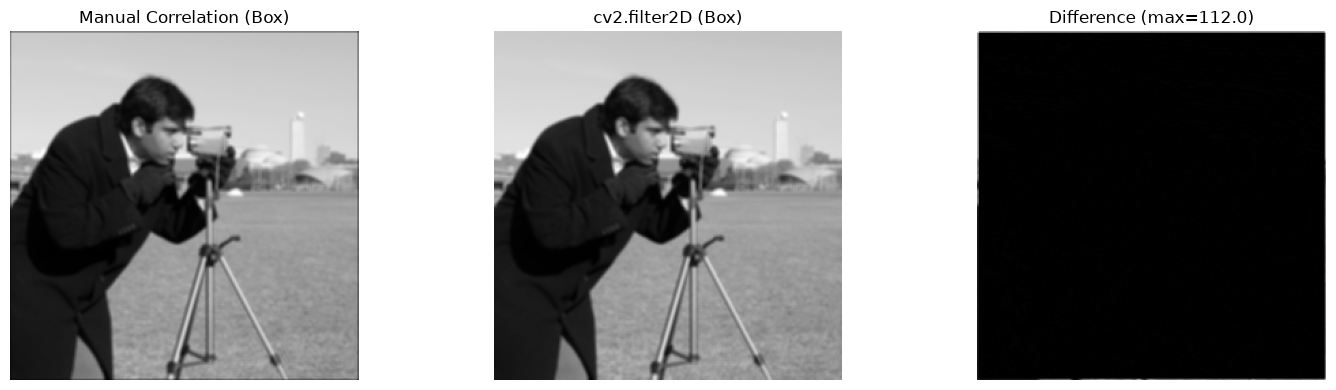

In [4]:
# Verification: compare manual correlation with OpenCV filter2D
cv_box = cv2.filter2D(test_img, -1, kernels["Box/Average (3×3)"])
manual_box = np.clip(results["Box/Average (3×3)"], 0, 255).astype(np.uint8)

diff = np.abs(cv_box.astype(float) - manual_box.astype(float))
print(f"Max difference (manual vs cv2.filter2D, box kernel): {diff.max():.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].imshow(manual_box, cmap='gray'); axes[0].set_title("Manual Correlation (Box)"); axes[0].axis('off')
axes[1].imshow(cv_box, cmap='gray'); axes[1].set_title("cv2.filter2D (Box)"); axes[1].axis('off')
axes[2].imshow(diff.astype(np.uint8), cmap='gray'); axes[2].set_title(f"Difference (max={diff.max():.1f})"); axes[2].axis('off')
plt.tight_layout(); plt.show()

## Task 4.2 – Unsharp Masking and High-Boost Filtering

Unsharp masking enhances edges in 3 steps:
1. **Blur** the original image f to get f_blur (using a Gaussian or box filter).
2. **Subtract**: mask = f − f_blur (the "unsharp mask" containing edge details).
3. **Add back**: g = f + k · mask, where k ≥ 1. When k = 1 it is standard unsharp masking; when k > 1 it is high-boost filtering.

All arithmetic is done in float to avoid uint8 overflow/underflow. Results are clipped to [0, 255].


=== Test Grayscale Image (shape: (256, 256)) ===


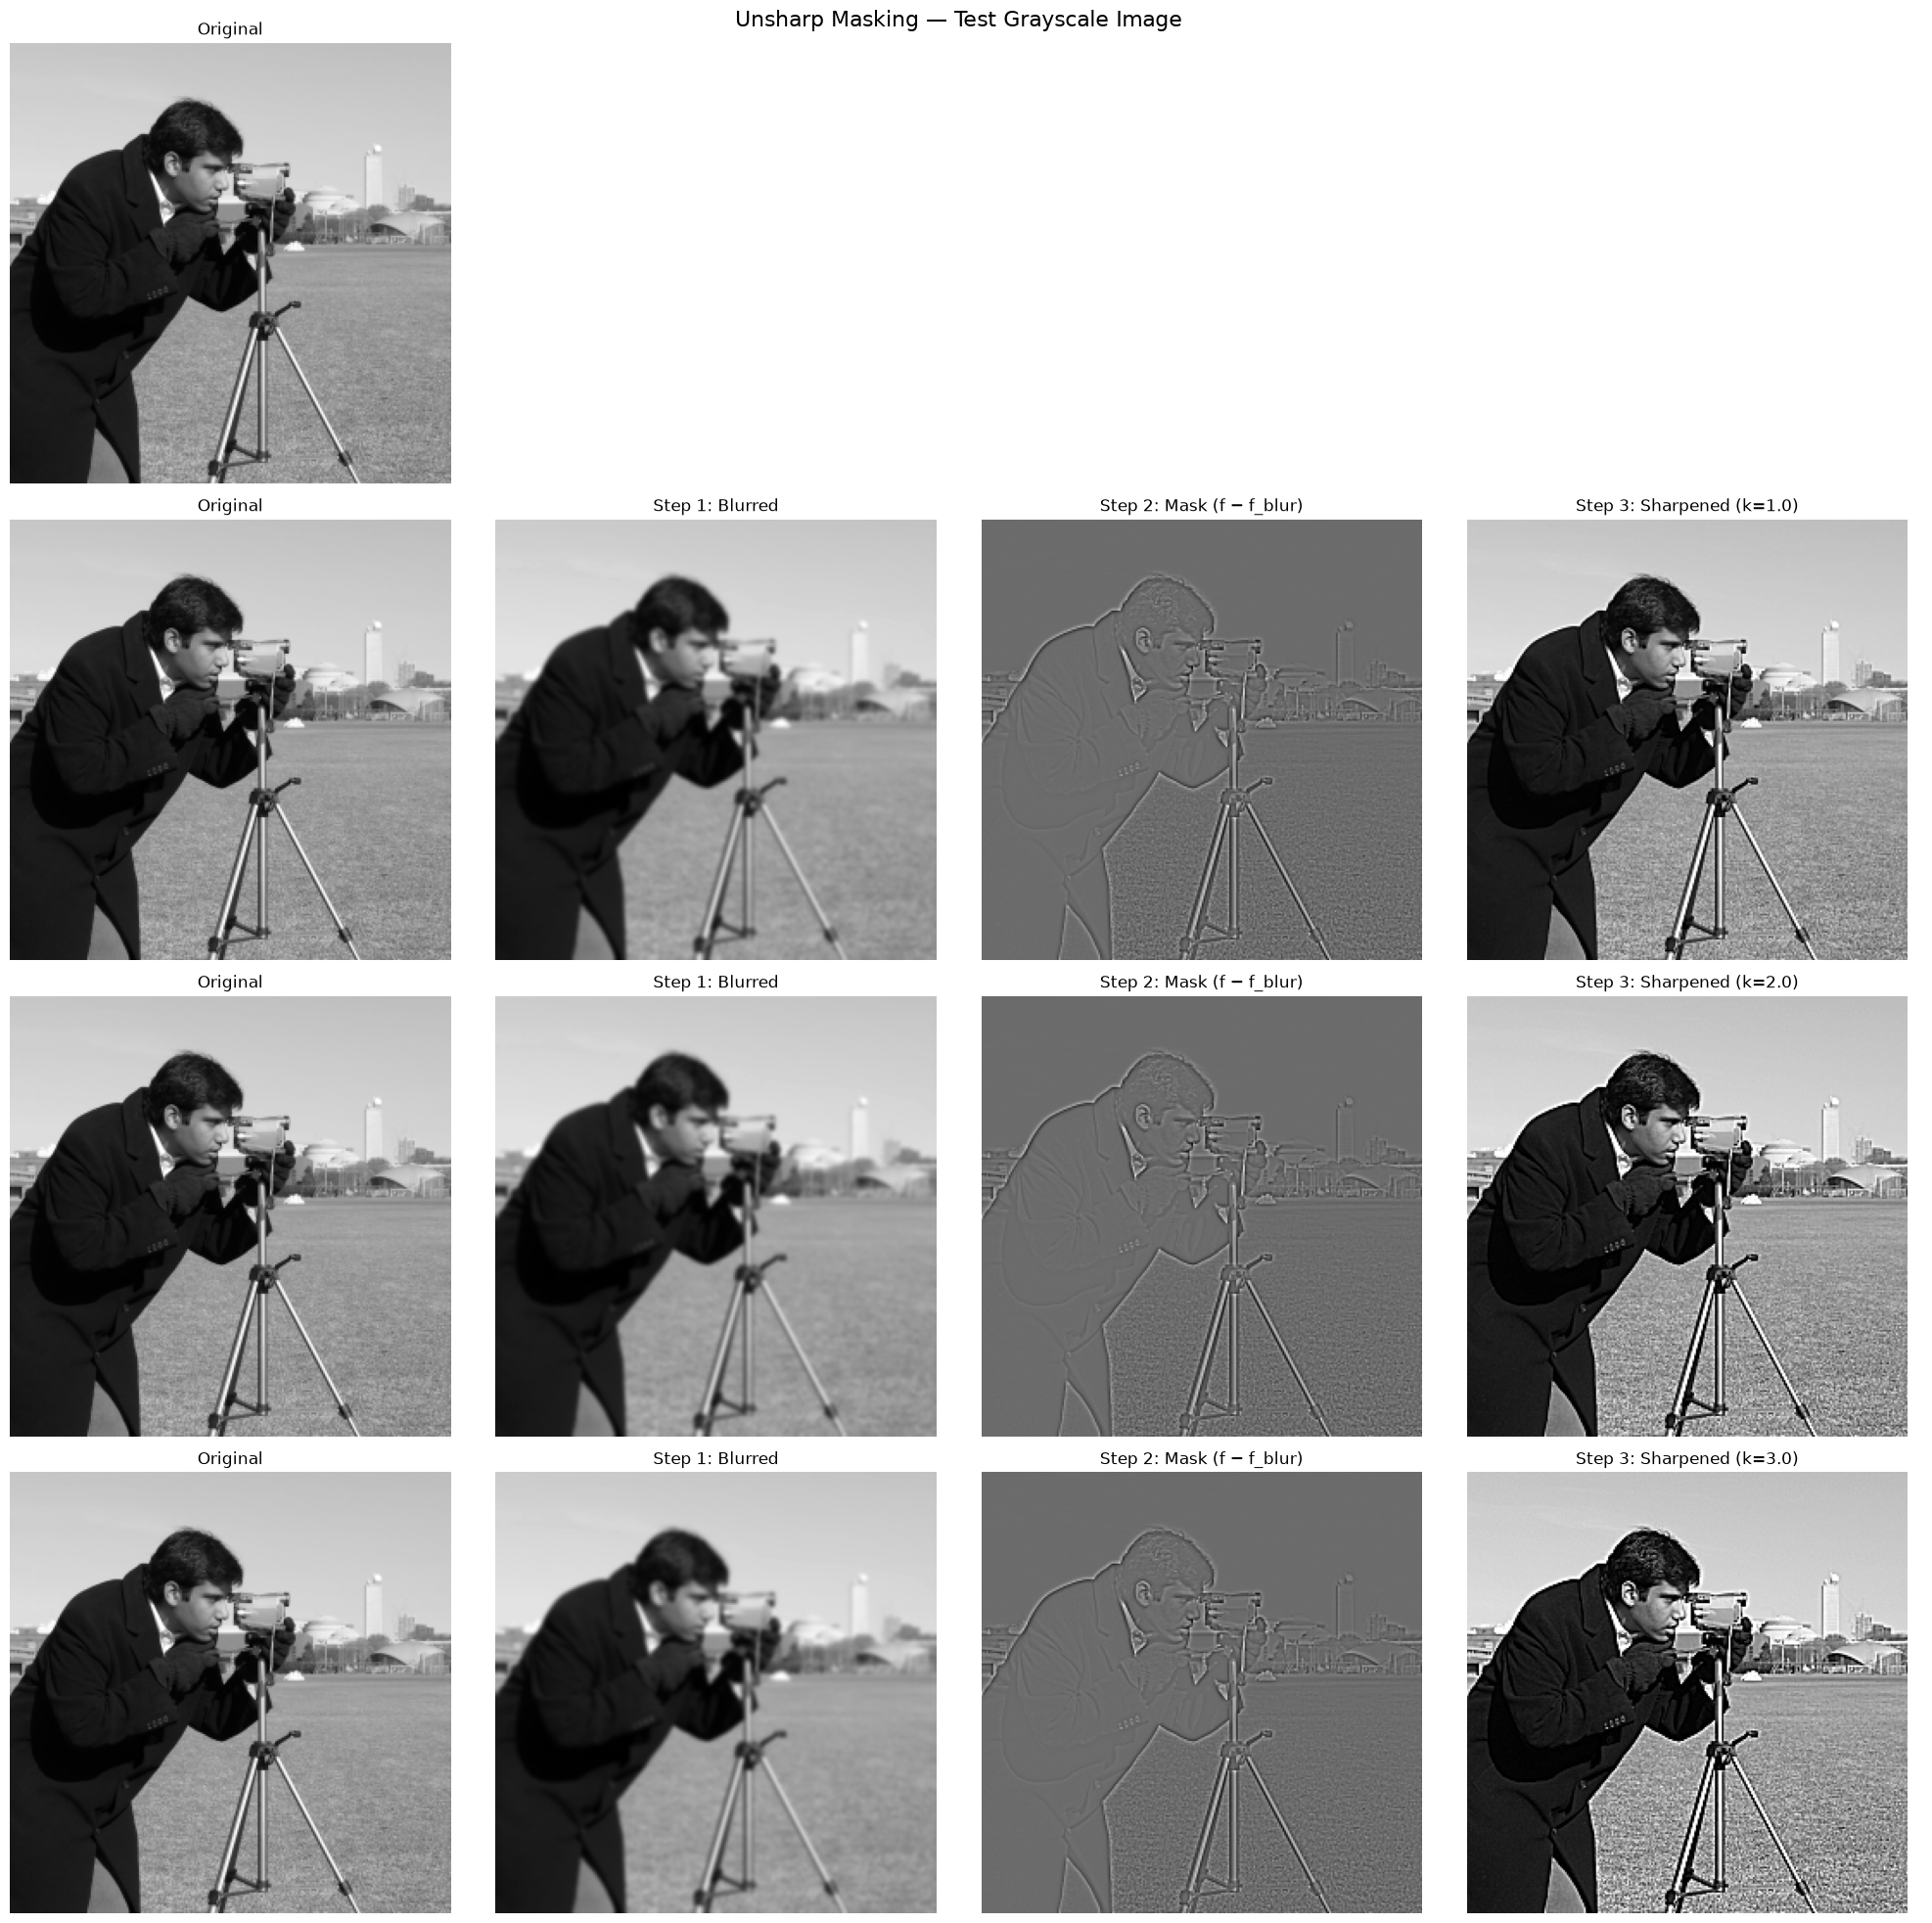


=== Moon / Second Image (shape: (512, 512)) ===


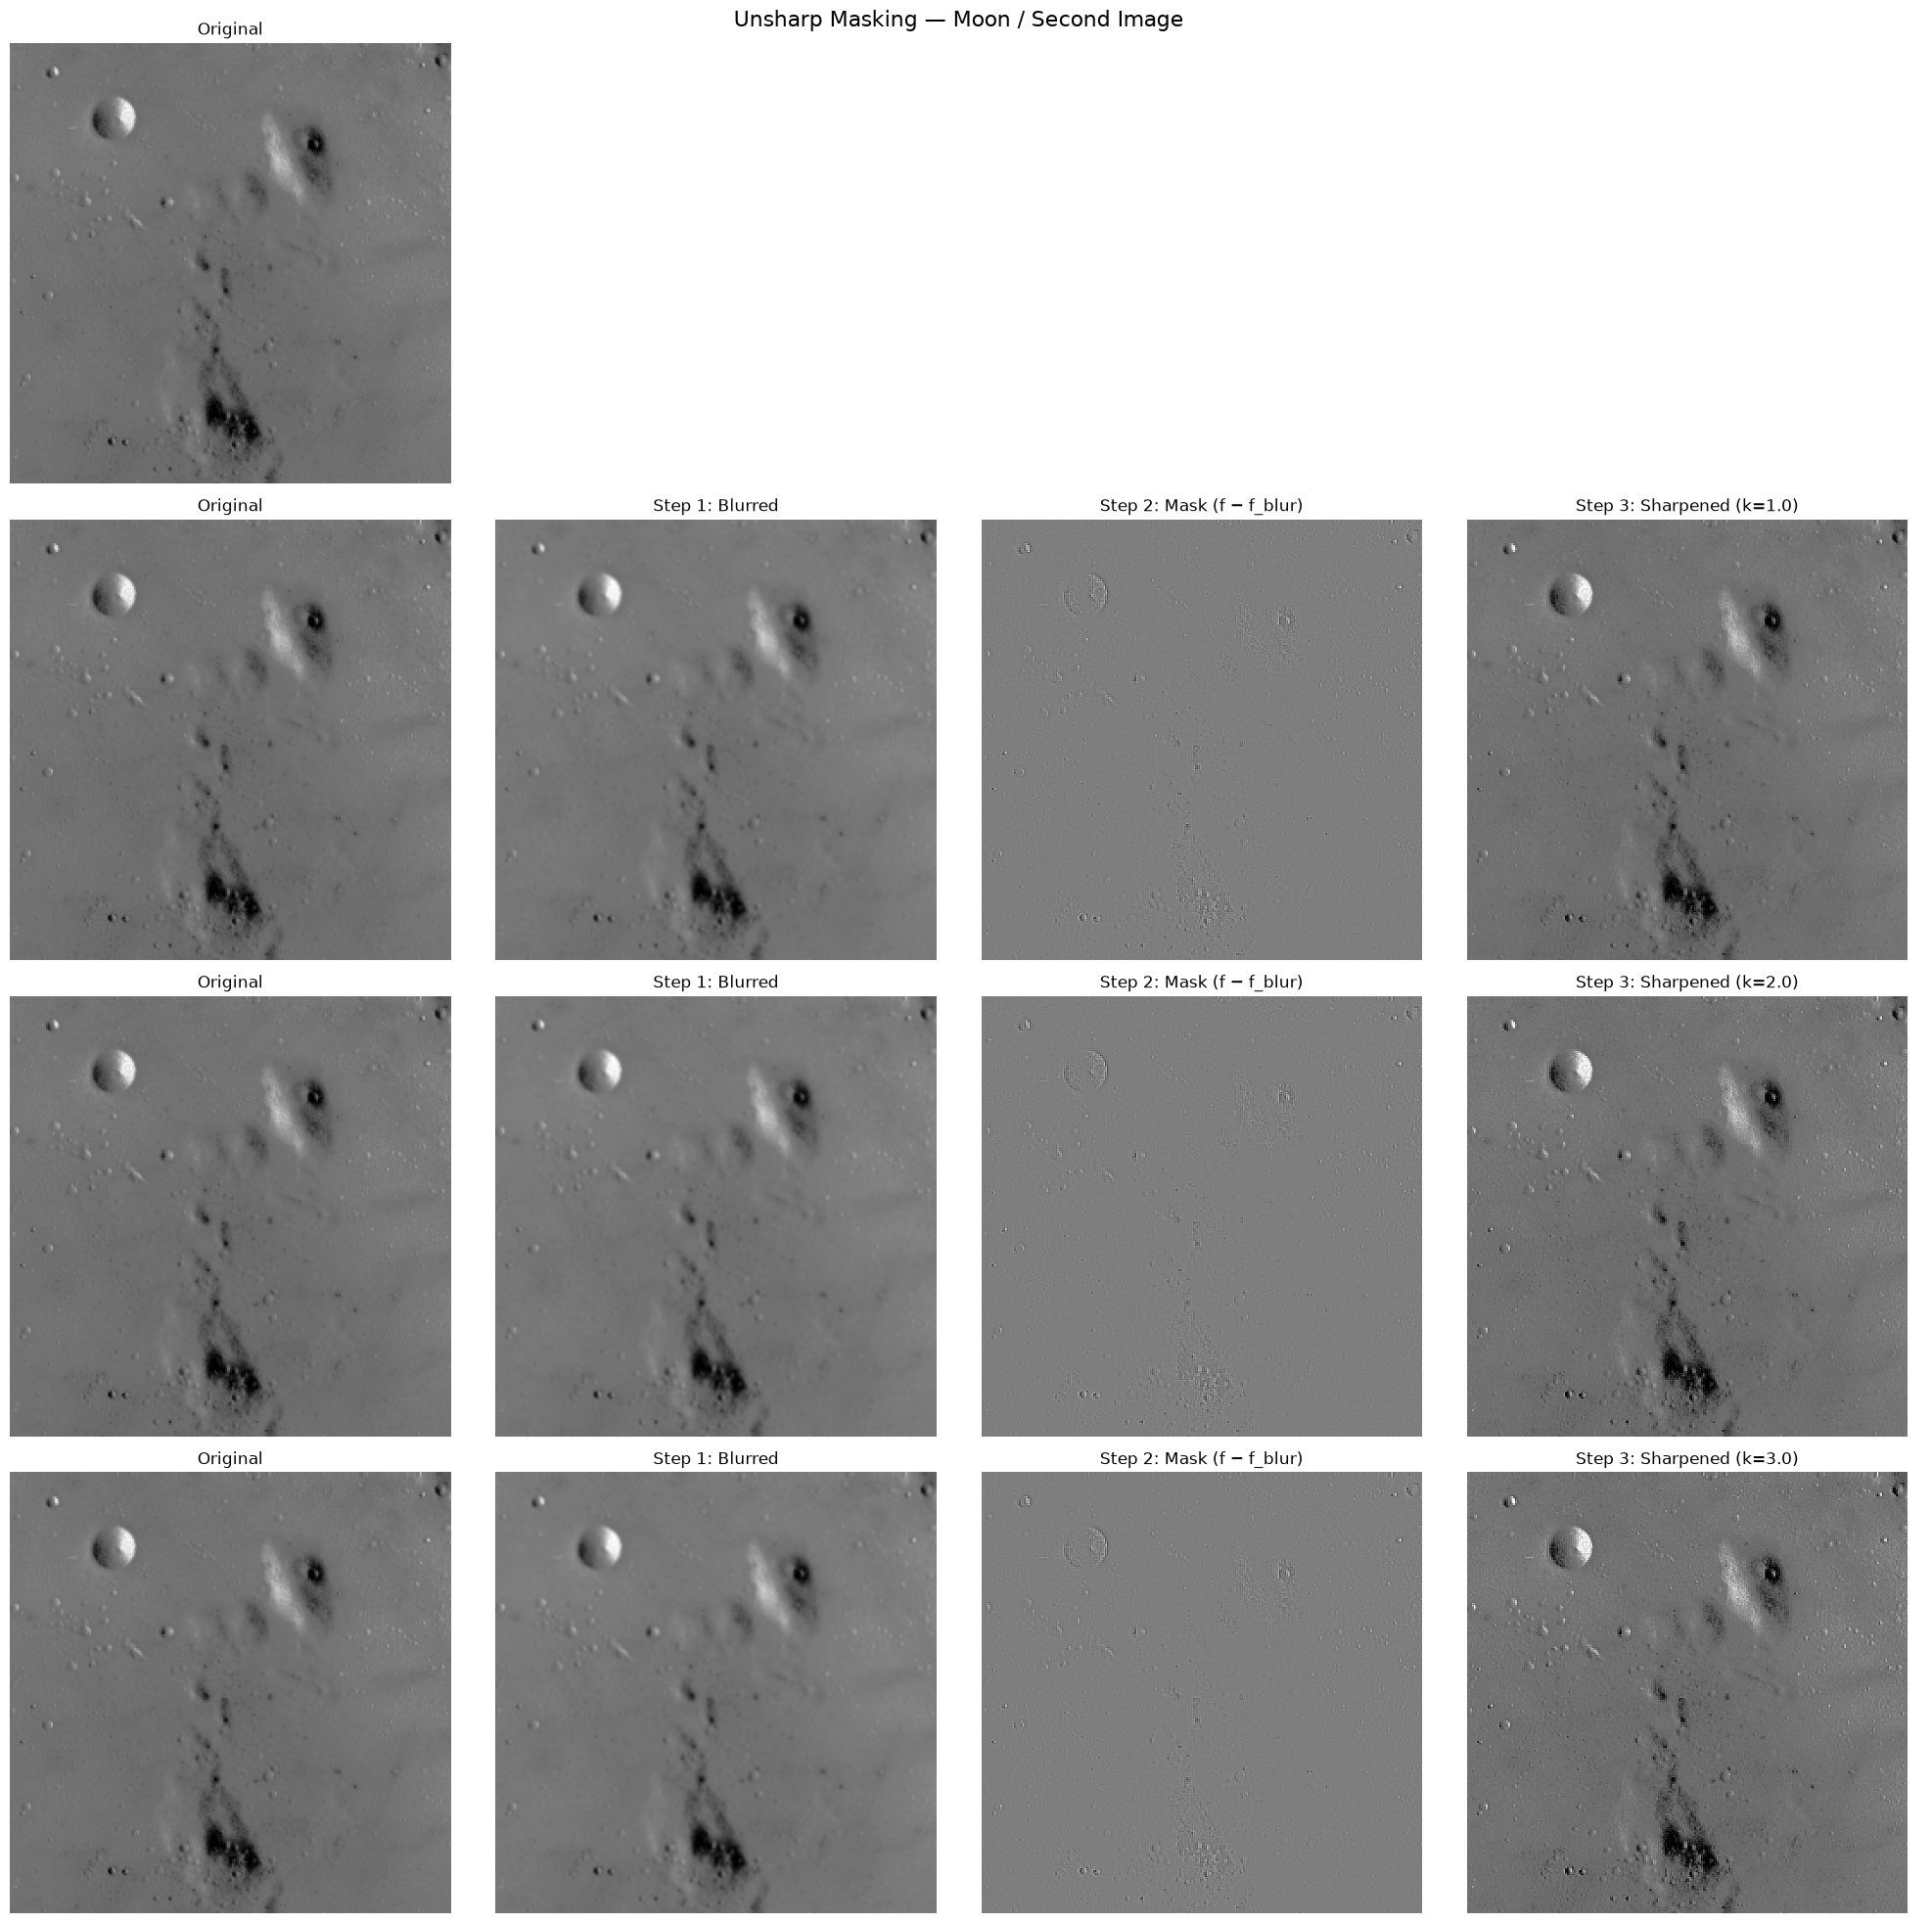

In [5]:
def unsharp_mask(image, kernel_size=5, k=1.0):
    """Apply unsharp masking / high-boost filtering.
    Step 1: Blur the image (Gaussian)
    Step 2: Compute mask = original - blurred
    Step 3: Result = original + k * mask
    Returns: blurred, mask, sharpened (all as float arrays)."""
    img_f = image.astype(np.float64)

    # Step 1: Gaussian blur
    blurred = cv2.GaussianBlur(img_f, (kernel_size, kernel_size), 0)

    # Step 2: Compute unsharp mask
    mask = img_f - blurred

    # Step 3: Add scaled mask back
    sharpened = img_f + k * mask

    return blurred, mask, sharpened

# Apply to the grayscale test image
# Also try on the Moon image (classic unsharp masking demo) - use our test image
images_to_process = [
    ("Test Grayscale Image", test_img),
]

# Also load a second image (astronaut converted to gray) for variety
from skimage import data as skdata
moon_img = skdata.moon() if hasattr(skdata, 'moon') else cv2.cvtColor(skdata.astronaut(), cv2.COLOR_RGB2GRAY)
images_to_process.append(("Moon / Second Image", moon_img))

k_values = [1.0, 2.0, 3.0]

for img_name, img in images_to_process:
    print(f"\n=== {img_name} (shape: {img.shape}) ===")

    fig, axes = plt.subplots(len(k_values) + 1, 4, figsize=(20, 5 * (len(k_values) + 1)))

    # Row 0: Original
    axes[0, 0].imshow(img, cmap='gray'); axes[0, 0].set_title("Original"); axes[0, 0].axis('off')
    axes[0, 1].axis('off'); axes[0, 2].axis('off'); axes[0, 3].axis('off')

    for row, k in enumerate(k_values, start=1):
        blurred, mask, sharpened = unsharp_mask(img, kernel_size=5, k=k)

        axes[row, 0].imshow(img, cmap='gray')
        axes[row, 0].set_title("Original")
        axes[row, 0].axis('off')

        axes[row, 1].imshow(np.clip(blurred, 0, 255).astype(np.uint8), cmap='gray')
        axes[row, 1].set_title("Step 1: Blurred")
        axes[row, 1].axis('off')

        # Normalise mask for display
        mask_display = mask - mask.min()
        if mask_display.max() > 0:
            mask_display = (mask_display / mask_display.max() * 255)
        axes[row, 2].imshow(mask_display.astype(np.uint8), cmap='gray')
        axes[row, 2].set_title("Step 2: Mask (f − f_blur)")
        axes[row, 2].axis('off')

        axes[row, 3].imshow(np.clip(sharpened, 0, 255).astype(np.uint8), cmap='gray')
        axes[row, 3].set_title(f"Step 3: Sharpened (k={k})")
        axes[row, 3].axis('off')

    plt.suptitle(f"Unsharp Masking — {img_name}", fontsize=16)
    plt.tight_layout(); plt.show()

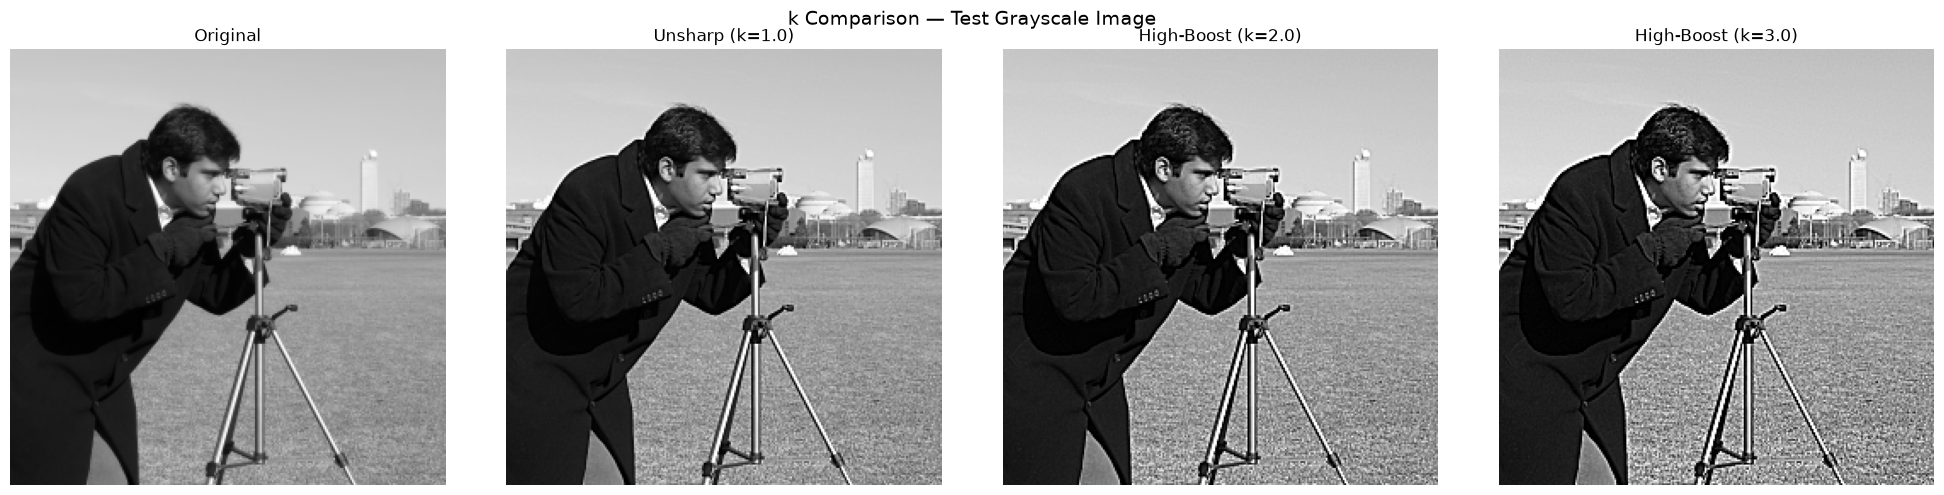

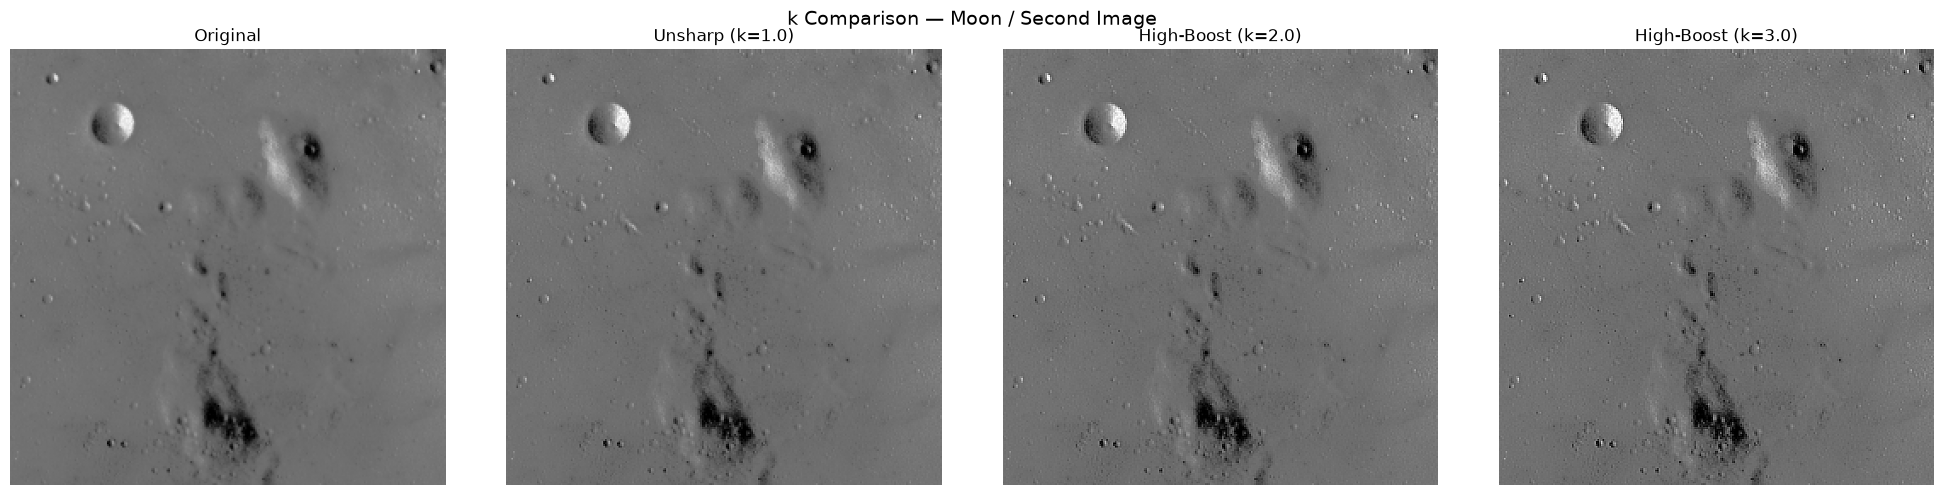

In [6]:
# Side-by-side comparison of different k values
for img_name, img in images_to_process:
    fig, axes = plt.subplots(1, len(k_values) + 1, figsize=(20, 5))
    axes[0].imshow(img, cmap='gray'); axes[0].set_title("Original"); axes[0].axis('off')
    for i, k in enumerate(k_values):
        _, _, sharpened = unsharp_mask(img, kernel_size=5, k=k)
        axes[i+1].imshow(np.clip(sharpened, 0, 255).astype(np.uint8), cmap='gray')
        label = "Unsharp" if k == 1.0 else "High-Boost"
        axes[i+1].set_title(f"{label} (k={k})"); axes[i+1].axis('off')
    plt.suptitle(f"k Comparison — {img_name}", fontsize=14)
    plt.tight_layout(); plt.show()

## Conclusion

In this assignment, we implemented two fundamental spatial filtering operations:

1. **2D Correlation** (Task 4.1): Manual implementation of correlation with zero-padding, applied with various kernels: box/average, Gaussian, Sobel (x and y), Laplacian, and sharpening. Results match OpenCV's `filter2D`.
2. **Unsharp Masking** (Task 4.2): The three-step process (blur → subtract → add back) effectively enhances edges. Standard unsharp masking (k=1) provides moderate sharpening; high-boost filtering (k>1) amplifies the effect. All computation uses float arithmetic to prevent overflow.